# Car Price Prediction: EDA, Data Cleaning & Linear Regression


Dataset: `CAR_DETAILS_FROM_CAR_DEKHO.csv` — used car listings with price, year, kilometers driven, fuel type, etc.

We will follow these steps:
1. Import libraries
2. Load the dataset
3. Inspect the data (head, info, describe, missing values)
4. Explore & clean the data (duplicates, outliers, visualizations)
5. Select features (X) and target (y)
6. Split data into training and testing sets
7. Create a Linear Regression model
8. Train the model
9. Predict on test data
10. Evaluate the model (MAE, MSE, RMSE, R²)
11. Predict new values and interpret coefficients

**Tip:** Run each cell in order (Shift + Enter). Read the comments — they explain what each line does.


## Step 1: Import libraries

In [1]:
# pandas -> for working with tabular data
import pandas as pd

# numpy -> for numeric operations
import numpy as np

# matplotlib and seaborn -> for making charts/plots
import matplotlib.pyplot as plt
import seaborn as sns

# train_test_split -> splits our data into training and testing sets
from sklearn.model_selection import train_test_split

# LinearRegression -> the machine learning model we will use
from sklearn.linear_model import LinearRegression

# metrics -> to check how good our model's predictions are
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make plots look a bit nicer
sns.set_style("whitegrid")

## Step 2: Load the dataset using pd.read_csv()

In [3]:
# Read the CSV file into a DataFrame
df = pd.read_csv("CAR_DETAILS_FROM_CAR_DEKHO.csv")

# Preview the first 5 rows
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## Step 3: Inspect the data

In [4]:
# head() -> shows the first 5 rows (already did this above, let's see a few more)
df.head(10)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner
7,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner
8,Hyundai Creta 1.6 VTVT S,2015,850000,25000,Petrol,Individual,Manual,First Owner
9,Maruti Celerio Green VXI,2017,365000,78000,CNG,Individual,Manual,First Owner


In [5]:
# info() -> shows column names, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [6]:
# describe() -> shows count, mean, std, min, max, and quartiles for numeric columns
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [7]:
# isnull().sum() -> counts missing values in each column
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Good news: this dataset has **no missing values**. But we still need to check for other issues like duplicate rows and outliers.

## Step 4: Explore & clean the data

Even with no missing values, real-world data often has:
- **Duplicate rows** (same car listed more than once)
- **Outliers** (unusually high/low prices or kilometers driven)
- **Categorical columns** that need to be understood before we use them

In [8]:
# Check for duplicate rows
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 763


In [9]:
# Remove duplicate rows, keep only the first occurrence
df = df.drop_duplicates(keep="first")

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (3577, 8)


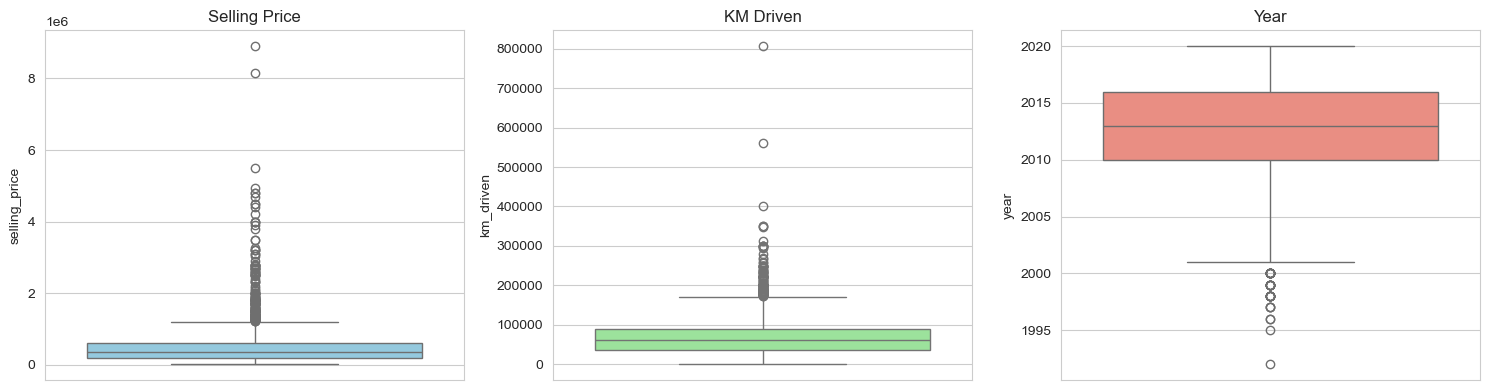

In [10]:
# Visualize numeric columns to spot outliers using boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(y=df["selling_price"], ax=axes[0], color="skyblue")
axes[0].set_title("Selling Price")

sns.boxplot(y=df["km_driven"], ax=axes[1], color="lightgreen")
axes[1].set_title("KM Driven")

sns.boxplot(y=df["year"], ax=axes[2], color="salmon")
axes[2].set_title("Year")

plt.tight_layout()
plt.show()

### Remove extreme outliers

In [11]:
# Function to remove outliers using the Percentile method
# We keep only the values between the 1st percentile and 99th percentile
# (this simply means: throw away the cheapest 1% and the most expensive 1% of cars)

def remove_outliers(data, column):
    lower_limit = data[column].quantile(0.01)   # value below which only 1% of data falls
    upper_limit = data[column].quantile(0.99)   # value above which only 1% of data falls

    # Keep only rows where the value is between these two limits
    return data[(data[column] >= lower_limit) & (data[column] <= upper_limit)]

# Apply outlier removal to selling_price and km_driven
df = remove_outliers(df, "selling_price")
df = remove_outliers(df, "km_driven")

print("Shape after removing outliers:", df.shape)

Shape after removing outliers: (3434, 8)


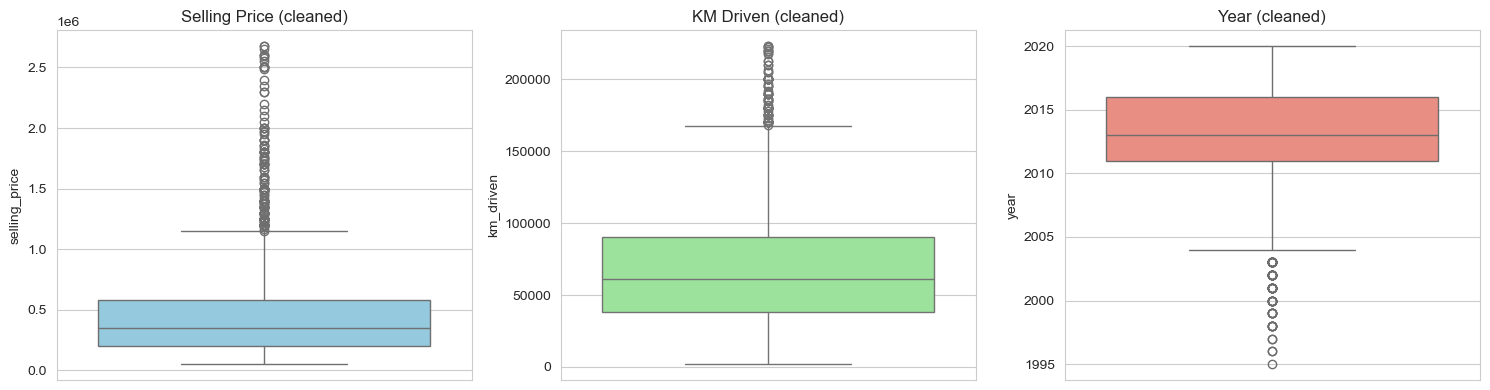

In [12]:
# Check the boxplots again -> extreme outliers should be gone
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(y=df["selling_price"], ax=axes[0], color="skyblue")
axes[0].set_title("Selling Price (cleaned)")

sns.boxplot(y=df["km_driven"], ax=axes[1], color="lightgreen")
axes[1].set_title("KM Driven (cleaned)")

sns.boxplot(y=df["year"], ax=axes[2], color="salmon")
axes[2].set_title("Year (cleaned)")

plt.tight_layout()
plt.show()

In [ ]:
# Visualize the distribution of selling price
plt.figure(figsize=(7, 4))
sns.histplot(df["selling_price"], bins=30, kde=True, color="steelblue")
plt.title("Distribution of Selling Price")
plt.xlabel("Selling Price")
plt.show()

In [ ]:
# Visualize categorical columns using count plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(x="fuel", data=df, hue="fuel", palette="Set2", legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Fuel Type")

sns.countplot(x="seller_type", data=df, hue="seller_type", palette="Set3", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Seller Type")

sns.countplot(x="transmission", data=df, hue="transmission", palette="Set1", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Transmission")

sns.countplot(x="owner", data=df, hue="owner", palette="Set2", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("Owner")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
# Scatter plot: how km_driven relates to selling_price
plt.figure(figsize=(7, 5))
sns.scatterplot(x="km_driven", y="selling_price", data=df, alpha=0.5, color="teal")
plt.title("KM Driven vs Selling Price")
plt.xlabel("KM Driven")
plt.ylabel("Selling Price")
plt.show()

In [ ]:
# Correlation heatmap for numeric columns
plt.figure(figsize=(5, 4))
numeric_cols = ["year", "selling_price", "km_driven"]
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numeric Columns")
plt.show()

**Observation:** `year` has a positive correlation with `selling_price` (newer cars cost more), while `km_driven` has a negative correlation (higher mileage means lower price).

## Step 5: Select features (X) and target (y)

Our **target (y)** is `selling_price` — the value we want to predict.

Our **features (X)** are the columns that help predict the price:
- `year`, `km_driven` (numeric)
- `fuel`, `seller_type`, `transmission`, `owner` (categorical)

We drop the `name` column since it has too many unique car names to be useful in a simple linear regression.

Categorical columns need to be converted into numbers using **one-hot encoding**
(this creates a separate 0/1 column for each category).

In [13]:
# Drop the 'name' column (too many unique values, not useful here)
df_model = df.drop(columns=["name"])

# One-hot encode categorical columns
# drop_first=True avoids redundant columns (prevents the "dummy variable trap")
df_model = pd.get_dummies(df_model, columns=["fuel", "seller_type", "transmission", "owner"], drop_first=True)

df_model.head()

,year,selling_price,km_driven,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,2007,60000,70000,False,False,False,True,True,False,True,False,False,False,False
1,2007,135000,50000,False,False,False,True,True,False,True,False,False,False,False
2,2012,600000,100000,True,False,False,False,True,False,True,False,False,False,False
3,2017,250000,46000,False,False,False,True,True,False,True,False,False,False,False
4,2014,450000,141000,True,False,False,False,True,False,True,False,True,False,False


In [14]:
# Separate features (X) and target (y)
X = df_model.drop(columns=["selling_price"])   # everything except the price
y = df_model["selling_price"]                  # the price, which we want to predict

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)
print("\nFeature columns:", list(X.columns))

Features (X) shape: (3434, 13)
Target (y) shape: (3434,)

Feature columns: ['year', 'km_driven', 'fuel_Diesel', 'fuel_Electric', 'fuel_LPG', 'fuel_Petrol', 'seller_type_Individual', 'seller_type_Trustmark Dealer', 'transmission_Manual', 'owner_Fourth & Above Owner', 'owner_Second Owner', 'owner_Test Drive Car', 'owner_Third Owner']


## Step 6: Split data into training and testing sets

We train the model on one part of the data (training set) and test how well it performs
on data it hasn't seen before (testing set). A common split is 80% train / 20% test.

In [15]:
# random_state ensures we get the same split every time we run this (for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set size:", X_train.shape[0])
print("Testing set size:", X_test.shape[0])

Training set size: 2747
Testing set size: 687


## Step 7: Create the Linear Regression model

In [17]:
# Create an instance of the Linear Regression model
model = LinearRegression()

## Step 8: Train the model using model.fit()

In [18]:
# fit() trains the model by finding the best-fit line through the training data
model.fit(X_train, y_train)

print("Model training complete!")

Model training complete!


## Step 9: Predict using model.predict()

In [19]:
# Use the trained model to predict selling prices on the unseen test data
y_pred = model.predict(X_test)

# Compare a few actual vs predicted values
comparison = pd.DataFrame({"Actual": y_test.values[:10], "Predicted": y_pred[:10].round(2)})
comparison

,Actual,Predicted
0,220000,216566.45
1,400000,429133.11
2,320000,354817.98
3,1300000,621352.64
4,380000,386333.16
5,240000,429133.11
6,725000,590904.91
7,450000,570732.52
8,160000,249045.40
9,750000,599546.56


## Step 10: Evaluate the model

We use these common regression metrics:
- **MAE (Mean Absolute Error)** — average absolute difference between actual and predicted values
- **MSE (Mean Squared Error)** — average of squared differences (penalizes bigger errors more)
- **RMSE (Root Mean Squared Error)** — square root of MSE, same unit as the target (price)
- **R² Score** — how much of the variation in price is explained by our model (closer to 1 is better)

In [20]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  (Mean Absolute Error):  {mae:,.2f}")
print(f"MSE  (Mean Squared Error):   {mse:,.2f}")
print(f"RMSE (Root Mean Sq. Error):  {rmse:,.2f}")
print(f"R2 Score:                    {r2:.3f}")

MAE  (Mean Absolute Error):  176,775.78
MSE  (Mean Squared Error):   66,286,068,981.41
RMSE (Root Mean Sq. Error):  257,460.81
R2 Score:                    0.486


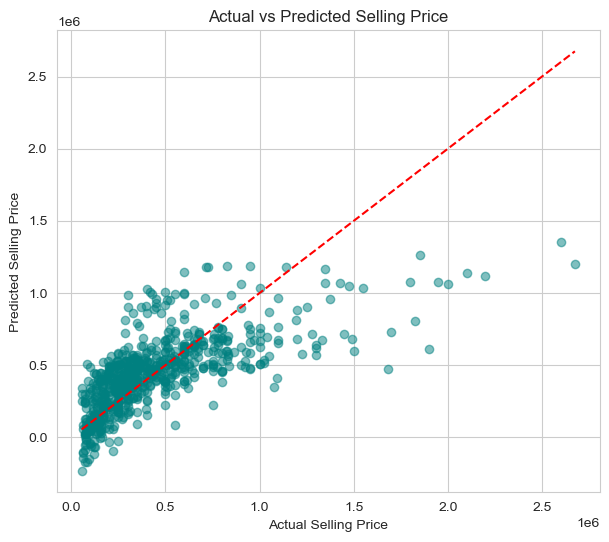

In [21]:
# Visualize actual vs predicted prices
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color="teal")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Selling Price")
plt.show()

The red dashed line represents perfect predictions. The closer our points are to this line, the better our model.

## Step 11: Predict new values and interpret coefficients

Let's predict the price for a brand-new (hypothetical) car listing, and understand
what each coefficient tells us about its effect on price.

In [22]:
# Create a new car listing with the same features/columns as our training data
# We build a fresh row of all zeros (as plain numbers), matching the same columns as X
new_car = pd.DataFrame(np.zeros((1, X.shape[1])), columns=X.columns)

# Now set realistic values for our new car
new_car["year"] = 2019
new_car["km_driven"] = 25000

# Example: mark fuel as Diesel and transmission as Manual (set the matching one-hot columns to 1)
if "fuel_Diesel" in new_car.columns:
    new_car["fuel_Diesel"] = 1
if "seller_type_Individual" in new_car.columns:
    new_car["seller_type_Individual"] = 1
if "owner_Second Owner" in new_car.columns:
    new_car["owner_Second Owner"] = 1

predicted_price = model.predict(new_car)[0]
print(f"Predicted selling price for the new car: Rs. {predicted_price:,.2f}")

Predicted selling price for the new car: Rs. 1,224,759.20


In [23]:
# Interpret the model's coefficients
# Each coefficient tells us how much selling_price changes when that feature increases by 1
# (while all other features stay the same)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
}).sort_values(by="Coefficient", ascending=False)

print(f"Intercept (base price when all features are 0): {model.intercept_:,.2f}\n")
coefficients

Intercept (base price when all features are 0): -64,151,630.96



,Feature,Coefficient
2,fuel_Diesel,249727.021138
11,owner_Test Drive Car,179714.470918
7,seller_type_Trustmark Dealer,143667.263660
0,year,32303.017060
5,fuel_Petrol,20843.254900
4,fuel_LPG,15664.264906
1,km_driven,-0.872243
10,owner_Second Owner,-21597.642594
9,owner_Fourth & Above Owner,-24743.183095
12,owner_Third Owner,-24884.278367


In [ ]:
# Visualize the coefficients
plt.figure(figsize=(8, 6))
sns.barplot(x="Coefficient", y="Feature", data=coefficients, hue="Feature", palette="coolwarm", legend=False)
plt.title("Effect of Each Feature on Selling Price")
plt.xlabel("Coefficient Value")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

**How to read this:**
- A **positive** coefficient means that feature tends to **increase** the selling price.
- A **negative** coefficient means that feature tends to **decrease** the selling price.
- For example, `year` usually has a positive coefficient (newer cars = higher price),
  while `km_driven` usually has a negative coefficient (more usage = lower price).


## Summary

| Step | What we did |
|------|-------------|
| 1 | Imported pandas, numpy, matplotlib, seaborn, and scikit-learn tools |
| 2 | Loaded the CAR DEKHO dataset |
| 3 | Inspected the data using head(), info(), describe(), isnull().sum() |
| 4 | Removed duplicates and outliers, visualized distributions and relationships |
| 5 | Selected features (X) and target (y), encoded categorical columns |
| 6 | Split the data into training (80%) and testing (20%) sets |
| 7 | Created a Linear Regression model |
| 8 | Trained the model with model.fit() |
| 9 | Made predictions with model.predict() |
| 10 | Evaluated the model using MAE, MSE, RMSE, and R² score |
| 11 | Predicted the price of a new car and interpreted the model's coefficients |

You now have a working Linear Regression model that predicts used car prices!


In [ ]:
# 1. Import
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Split data into train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Create the model
model = LinearRegression()

# 4. Train (fit) the model on training data
model.fit(X_train, y_train)

# 5. Predict on test data
y_pred = model.predict(X_test)

# 6. Predict on brand-new/custom data
model.predict(new_data)          # new_data must have the same columns as X

# 7. Look at what the model learned
model.coef_            # the weight/effect of each feature
model.intercept_       # the base value when all features are 0

# 8. Evaluate performance
mean_absolute_error(y_test, y_pred)
mean_squared_error(y_test, y_pred)
mean_squared_error(y_test, y_pred) ** 0.5     # RMSE
r2_score(y_test, y_pred)

# 9. Check model accuracy on train/test directly (R² shortcut)
model.score(X_train, y_train)     # R² on training data
model.score(X_test, y_test)       # R² on test data